# Random matrix theory: separating signal from noise
The previous notebook showed that the correlation matrix has a clear structure: a market layer that every stock shares, with sector blocks on top. What it couldn’t tell us is how much of that matrix we can actually trust. Some of it is real structure, but some of it is just noise from estimating 2,628 correlations out of a limited amount of data. This notebook tries to separate the two.

The tool for this is random matrix theory. It started in nuclear physics in the 1950s, when Eugene Wigner modelled the energy levels of heavy atomic nuclei as the eigenvalues of random matrices, because the real interactions were far too complicated to calculate. The result I use here came later, in 1967, from the mathematicians Marchenko and Pastur, and in 1999 two groups of physicists, Laloux et al. and Plerou et al., applied it to stock market correlations.

The idea is simple. Suppose the 73 stocks were completely unrelated. A correlation matrix estimated from T days of their returns still wouldn’t come out perfectly clean, because random co-movements creep in by chance. The Marchenko–Pastur law says exactly how far that pure noise spreads the eigenvalues: with q = N/T, they land between (1 − √q)² and (1 + √q)². So any eigenvalue of the real matrix well outside that range points to genuine structure, and anything inside it can’t be told apart from noise.

It helps to think of each eigenvector as a portfolio, a particular set of weights across the 73 stocks. Its eigenvalue is the variance of that portfolio, with every stock scaled to the same volatility and the weights scaled so their squares add up to 1. The eigenvalues always add up to N, so together they show how the total risk is shared out.

## 1. Data and eigenvalues

Returns are loaded with `load_returns()` from `src/data.py`, which reads the same 73 stocks and 2,513 trading days used in the EDA notebook. The random matrix tools are in `src/rmt.py`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_returns
from src.rmt import mp_bounds, mp_density, eig, n_signal, ipr, clean_corr, clean_cov, shuffle_eigs, min_var

R, sec = load_returns()
T, N = R.shape
q = N / T
C = R.corr().to_numpy()
w, v = eig(C)
lo, hi = mp_bounds(q)
s2 = 1 - w[0] / N

pd.Series({
    "stocks (N)": N,
    "days (T)": T,
    "q = N/T": q,
    "noise range, lower edge": lo,
    "noise range, upper edge": hi,
    "largest eigenvalue": w[0],
    "share of total variance": w[0] / N,
    "eigenvalues above the edge": n_signal(w, q),
    "above the edge, market removed": n_signal(w, q, s2),
}).round(3)

stocks (N)                          73.000
days (T)                          2513.000
q = N/T                              0.029
noise range, lower edge              0.688
noise range, upper edge              1.370
largest eigenvalue                  26.532
share of total variance              0.363
eigenvalues above the edge           7.000
above the edge, market removed      12.000
dtype: float64

In [2]:
pd.DataFrame({
    "eigenvalue": w[:10],
    "share of variance": w[:10] / N,
    "cumulative share": np.cumsum(w[:10]) / N,
}, index=pd.RangeIndex(1, 11, name="rank")).round(3)

,eigenvalue,share of variance,cumulative share
rank,,,
1,26.532,0.363,0.363
2,5.561,0.076,0.440
3,4.190,0.057,0.497
4,2.075,0.028,0.525
5,1.565,0.021,0.547
6,1.457,0.020,0.567
7,1.395,0.019,0.586
8,1.272,0.017,0.603
9,1.121,0.015,0.619


## 2. The spectrum against the noise prediction

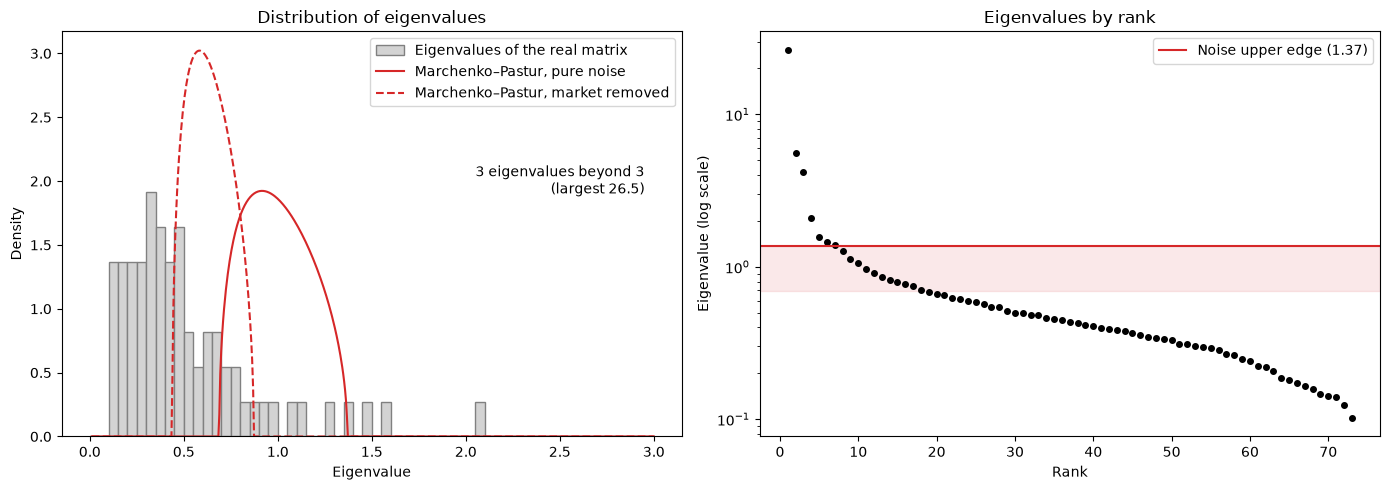

In [3]:
x = np.linspace(0.01, 3, 600)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))

a.hist(w, bins=np.linspace(0, 3, 61), weights=np.full(N, 1 / (N * 0.05)), color="lightgrey", edgecolor="grey", label="Eigenvalues of the real matrix")
a.plot(x, mp_density(x, q), color="tab:red", label="Marchenko–Pastur, pure noise")
a.plot(x, mp_density(x, q, s2), color="tab:red", ls="--", label="Marchenko–Pastur, market removed")
m = int((w > 3).sum())
a.text(2.95, a.get_ylim()[1] * 0.6, f"{m} eigenvalue{'s' if m > 1 else ''} beyond 3\n(largest {w[0]:.1f})", ha="right")
a.set_xlabel("Eigenvalue")
a.set_ylabel("Density")
a.set_title("Distribution of eigenvalues")
a.legend()

b.semilogy(range(1, N + 1), w, "o", ms=4, color="black")
b.axhline(hi, color="tab:red", label=f"Noise upper edge ({hi:.2f})")
b.axhspan(lo, hi, color="tab:red", alpha=0.1)
b.set_xlabel("Rank")
b.set_ylabel("Eigenvalue (log scale)")
b.set_title("Eigenvalues by rank")
b.legend()

plt.tight_layout()
plt.savefig("../figures/eigen_spectrum.png", dpi=150, bbox_inches="tight")

In [4]:
(w < lo).sum()

np.int64(55)

**How to read this figure:** 
Both panels show the same 73 eigenvalues in two different ways. On the left is a histogram: each grey bar shows how many eigenvalues fall in that range, so tall bars mean lots of eigenvalues of that size. I cut the axis at 3, because the largest eigenvalues are far bigger than the rest and would squash everything else. The solid red curve is where I’d expect the eigenvalues to land if the matrix were pure noise. The dashed curve is an adjustment from Laloux et al. (1999): the market eigenvalue alone takes up 36% of the total variance, which leaves less for everything else, so I shrank the noise variance to 1 − λ₁/N, which pulls the noise band down and to the left.

On the right, each dot is one eigenvalue, sorted from largest to smallest. The vertical axis is on a log scale, so the market eigenvalue at 26.5 fits on the same chart as the small ones. The shaded band is the noise range from 0.69 to 1.37. A dot inside the band could just be noise. A dot outside it, above or below, points to something real.

**What stands out:** 
Seven dots sit above the band, and the first is in a league of its own at 26.5. Those are the parts of the matrix we can trust. What surprised me is the left panel: if the other 66 eigenvalues were pure noise, they should pile up under one of the red curves, but they don’t fit either. 55 of them sit below the lower edge of 0.69, some as low as 0.10, which pure noise can’t produce. Part of the reason is that the seven real factors absorb 59% of the variance and push everything else down. The other part, which I analyze in section 4, is that some of the smallest eigenvalues belong to pairs of very similar stocks, where going long one and short the other leaves almost no risk.

**What it means:** 
With ten years of data, the noise band is narrow, and most of what sits outside it is real, so in the full sample, noise isn’t really the main problem. It matters much more in the one-year windows I use for the backtest, where the band widens to roughly 0.21 to 2.37 and far more of the matrix becomes indistinguishable from noise.

## 3. Shuffle test

In section 2 I compared the eigenvalues with the Marchenko–Pastur law, but that law assumes well-behaved returns, and the previous notebook showed that real returns are fat-tailed. So I wanted to check whether fat tails on their own could push eigenvalues past the edge. To do that, I shuffled each stock’s returns in time, separately for every stock. Each stock keeps exactly the same returns, fat tails included, but they no longer line up day by day, so any real correlation between stocks is destroyed. I repeated this 20 times, which gives me a noise benchmark built from my own data rather than from theory.

Marchenko–Pastur upper edge                     1.370
largest shuffled eigenvalue (average)           1.344
largest shuffled eigenvalue (maximum)           1.381
real eigenvalues above the shuffled maximum     7.000
smallest shuffled eigenvalue (minimum)          0.691
real eigenvalues below the shuffled minimum    55.000
dtype: float64

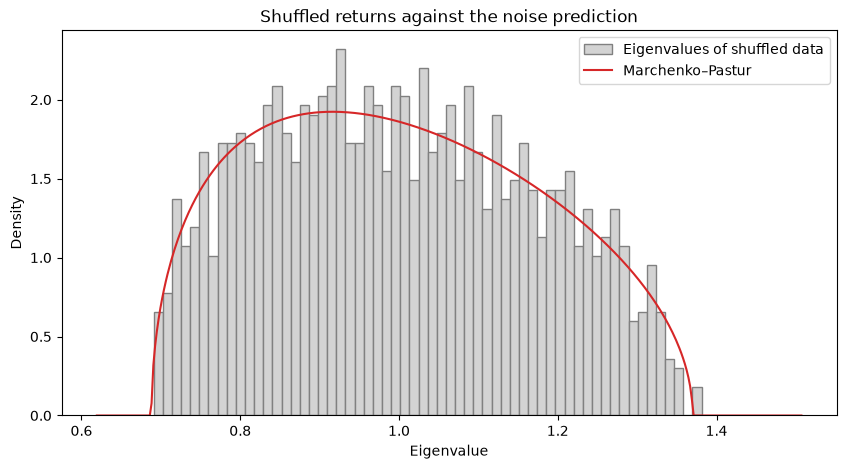

In [5]:
ws = shuffle_eigs(R.to_numpy(), n=20)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(ws.ravel(), bins=60, density=True, color="lightgrey", edgecolor="grey", label="Eigenvalues of shuffled data")
xs = np.linspace(lo * 0.9, hi * 1.1, 400)
ax.plot(xs, mp_density(xs, q), color="tab:red", label="Marchenko–Pastur")
ax.set_xlabel("Eigenvalue")
ax.set_ylabel("Density")
ax.set_title("Shuffled returns against the noise prediction")
ax.legend()
plt.savefig("../figures/shuffle_test.png", dpi=150, bbox_inches="tight")

pd.Series({
    "Marchenko–Pastur upper edge": hi,
    "largest shuffled eigenvalue (average)": ws[:, 0].mean(),
    "largest shuffled eigenvalue (maximum)": ws[:, 0].max(),
    "real eigenvalues above the shuffled maximum": (w > ws[:, 0].max()).sum(),
     "smallest shuffled eigenvalue (minimum)": ws[:, -1].min(),
    "real eigenvalues below the shuffled minimum": (w < ws[:, -1].min()).sum(),
}).round(3)

**How to read this figure:** The grey bars are the eigenvalues from all 20 shuffled versions of the data, 1,460 in total, and the red curve is the Marchenko–Pastur prediction for pure noise. If fat tails distorted the noise band, the bars would spill past the curve.

**What stands out:** They don’t. The shuffled eigenvalues follow the curve closely, and the largest of them reached 1.38, almost exactly the theoretical upper edge of 1.37. So fat tails barely move the noise band at this sample size, and the theory is reliable for my data. All seven of our real eigenvalues still sit above the largest shuffled one, although the seventh only just makes it (1.395 against 1.381), so I treated the last one or two factors as borderline. At the other end, 55 of our real eigenvalues fall below the smallest shuffled one, which confirms that those very small eigenvalues are real structure, not noise. Putting the two together, 62 of the 73 eigenvalues fall outside the range that noise can produce, and only 11 sit inside it. With ten years of data, we can deduce that most of the correlation matrix is infact real.

## 4. What the eigenvectors represent

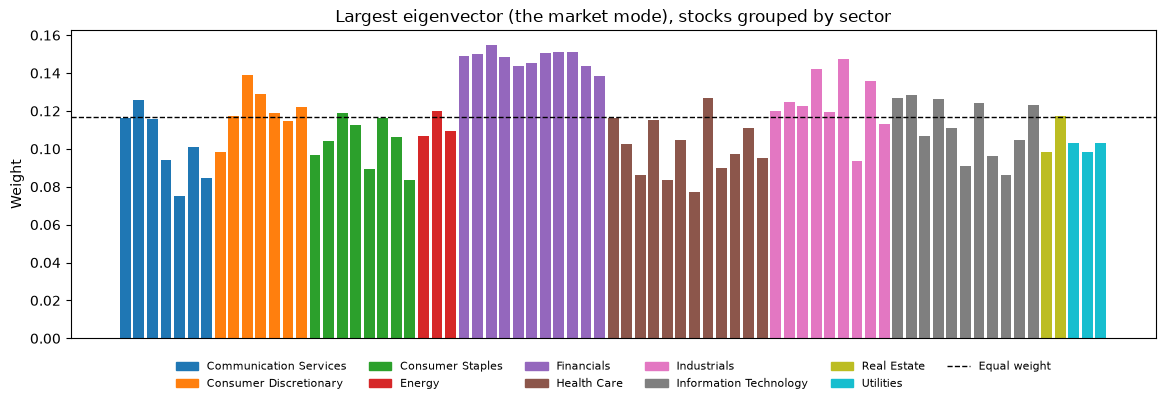

In [6]:
V = pd.DataFrame(v[:, :6], index=R.columns, columns=[f"v{i}" for i in range(1, 7)])
V = V * np.sign(V.sum())
colours = dict(zip(sec.unique(), sns.color_palette("tab10", sec.nunique())))

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(N), V["v1"], color=sec.map(colours))
ax.axhline(1 / np.sqrt(N), color="black", ls="--", lw=1, label="Equal weight")
ax.set_xticks([])
ax.set_ylabel("Weight")
ax.set_title("Largest eigenvector (the market mode), stocks grouped by sector")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()]
ax.legend(handles + ax.get_legend_handles_labels()[0], list(colours) + ["Equal weight"], ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.04), frameon=False)
plt.savefig("../figures/market_mode.png", dpi=150, bbox_inches="tight")

**How to read this figure:** Each bar is one stock’s weight in the largest eigenvector, coloured by sector, and the dashed line is the weight every stock would have if they all counted equally (1/√73 ≈ 0.117).

**What we find:** Every weight was positive, so this eigenvector is a portfolio that simply holds the whole market, which is why I called it the market mode. It accounted for 36% of our total variance. The weights weren’t equal, though. Financials sat well above the line, followed by industrials, while health care, consumer staples and communication services sat below it. That matched what we saw in the EDA, where financials were the most connected sector: the stocks that move most with everything else carried the most weight in the market factor.

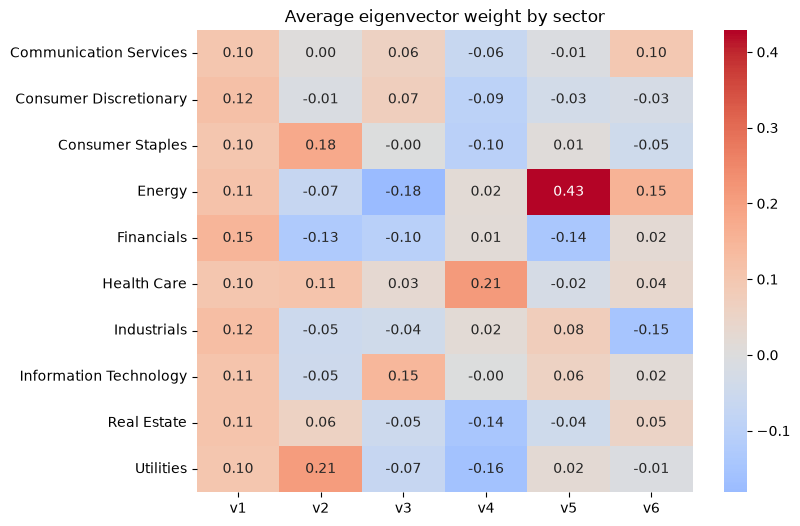

In [7]:
L = V.groupby(sec).mean()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(L, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_ylabel("")
ax.set_title("Average eigenvector weight by sector")
plt.savefig("../figures/sector_loadings.png", dpi=150, bbox_inches="tight")

In [8]:
pd.DataFrame({c: [", ".join(V[c].nlargest(5).index), ", ".join(V[c].nsmallest(5).index)] for c in V.columns[1:5]},
             index=["most positive", "most negative"]).T

,most positive,most negative
v2,"CL, PG, PEP, DUK, SO","GS, C, COF, MS, BAC"
v3,"AMZN, ADBE, MSFT, NVDA, NFLX","XOM, CVX, COP, USB, WFC"
v4,"BMY, PFE, MRK, AMGN, GILD","NEE, DUK, SPG, SO, KO"
v5,"COP, XOM, CVX, CAT, DE","USB, WFC, BAC, COF, JPM"


**How to read this:** The heatmap shows the average weight each sector got in the first six eigenvectors, and the table lists the five stocks with the most positive and most negative weight in v2 to v5. One detail matters here: apart from v1, the sign of an eigenvector is arbitrary, since flipping every weight gives the same factor. So “positive” and “negative” just mean opposite sides of the same bet.

**What we find:** Without ever being told which sector each stock belongs to, the eigenvectors picked out familiar economic groupings:

-v2 (λ = 5.6), defensive vs cyclical: consumer staples and utilities (CL, PG, PEP, DUK, SO) on one side, the big banks (GS, C, COF, MS, BAC) on the other.

-v3 (λ = 4.2), growth vs value: tech and growth names (AMZN, ADBE, MSFT, NVDA, NFLX) against oil companies and banks (XOM, CVX, COP, USB, WFC).

-v4 (λ = 2.1), pharma vs interest-rate-sensitive stocks: drug makers (BMY, PFE, MRK, AMGN, GILD) against utilities, real estate and Coca-Cola (NEE, DUK, SPG, SO, KO), which tend to trade like bonds.

-v5 (λ = 1.6), commodities vs banks: energy dominated it (average weight 0.43), along with heavy machinery (CAT, DE), against regional and retail banks (USB, WFC, BAC, COF, JPM).

-v6 (λ = 1.46) didn’t have a clear story, and its eigenvalue was borderline in the shuffle test, so I didn’t try to interpret it. These factors lined up closely with the predictions from the EDA, especially the cyclical-versus-defensive and growth-versus-value splits.

To see how spread out each eigenvector was, I used the inverse participation ratio (IPR), the sum of each weight to the fourth power. It’s about 1/N when every stock has the same weight, 1 when a single stock carries all of it, and around 3/N for an eigenvector that is pure noise. Roughly, 1/IPR tells you how many stocks an eigenvector really involves.

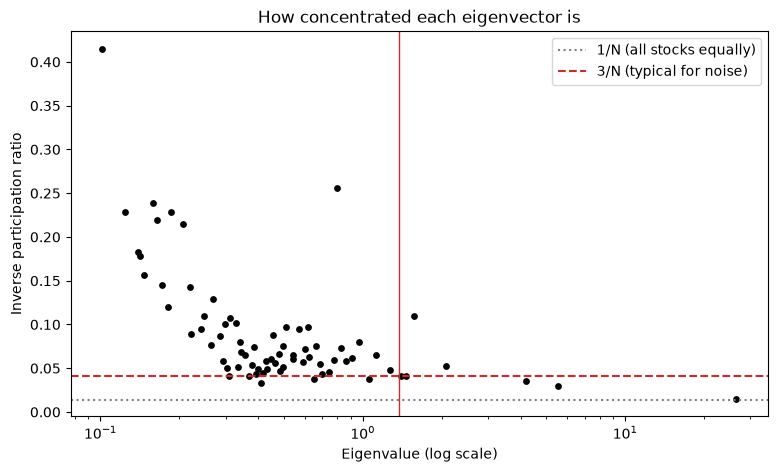

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(w, ipr(v), s=15, color="black")
ax.axhline(1 / N, color="grey", ls=":", label="1/N (all stocks equally)")
ax.axhline(3 / N, color="tab:red", ls="--", label="3/N (typical for noise)")
ax.axvline(hi, color="tab:red", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Eigenvalue (log scale)")
ax.set_ylabel("Inverse participation ratio")
ax.set_title("How concentrated each eigenvector is")
ax.legend()
plt.savefig("../figures/ipr.png", dpi=150, bbox_inches="tight")

In [10]:
for k in [1, 2, 3]:
    s = pd.Series(v[:, -k], index=R.columns)
    print(round(w[-k], 3), s[s.abs().nlargest(4).index].round(2).to_dict())
j = np.where((w > 0.5) & (w < 1.2))[0]
j = j[np.argmax(ipr(v)[j])]
s = pd.Series(v[:, j], index=R.columns)
print("outlier", round(w[j], 3), s[s.abs().nlargest(4).index].round(2).to_dict())

0.102 {'BAC': -0.77, 'JPM': 0.48, 'MS': 0.26, 'GS': -0.23}
0.124 {'MS': 0.58, 'GS': -0.56, 'BAC': 0.29, 'CVX': -0.25}
0.139 {'CVX': -0.58, 'XOM': 0.46, 'MS': -0.33, 'HD': 0.26}
outlier 0.799 {'UNH': 0.7, 'WMT': -0.28, 'NKE': -0.26, 'GILD': -0.2}


**How to read this figure:** Each dot is one eigenvector, placed by its eigenvalue (horizontally, on a log scale) and its IPR (vertically). A low IPR means the eigenvector is spread across many stocks; a high IPR means a handful of stocks carry most of the weight. The red vertical line is the noise edge from section 2.

**What we found:** The market mode sat right on 1/N, about as spread out as an eigenvector can be, and v2 and v3 were also spread across many stocks, which is what broad economic factors should look like. v5 stood out with an IPR of about 0.11 because it was concentrated on the three energy stocks.

The interesting part is the far left. The smallest eigenvalues had the highest IPRs, up to 0.41, so just a few stocks dominated them. The cell above shows which: the smallest eigenvalue (0.10) was essentially Bank of America against JPMorgan, the next (0.12) Morgan Stanley against Goldman Sachs, and the third (0.14) Chevron against Exxon. Going long one company and short its near-twin cancels most of their shared movement, which leaves very little risk and explains why these eigenvalues are so small. So they’re real structure rather than noise, and they help explain the 55 eigenvalues below the noise band in section 2.

The one odd point, at an eigenvalue of 0.8 with an IPR of 0.26, was dominated by a single stock, UnitedHealth (weight 0.70). It reflects company-specific moves that nothing else in the dataset shared, most notably its sharp fall in 2025.

**Why it matters:** These near-riskless pairs are exactly what a minimum-variance optimizer goes looking for. The structure is real, but the very low risk they show in our sample is fragile, so an optimizer can end up making large long-short bets on them. Cleaning lifts these small eigenvalues up to the average, which stops that from happening, at the cost of throwing away some genuine information. I will come back to this trade-off in section 5.

## 5. Cleaning the matrix

To clean the matrix, I kept the seven eigenvalues above the noise edge and replaced all the others, including the 55 below the band, with their average, so the total variance stayed the same. The eigenvectors were left exactly as they were. Finally, I rescaled the matrix so every stock still had a correlation of 1 with itself. This is the eigenvalue clipping method of Laloux et al. (1999).
The real test is out of sample. For each year, I built a minimum-variance portfolio from one year of data and then held it for the following year. The predicted volatility is the risk the estimated matrix said the portfolio would have, and the realized volatility is what actually happened. If the matrix is noisy, the optimiser becomes overconfident, so I expected its predicted risk to fall well short of the realised risk.

The reason is that the optimizer doesn’t just read the matrix; it searches it for the lowest-risk combination of stocks. Some directions look less risky than they really are purely by chance, and the optimizer can’t tell those apart from genuinely safe ones, so it ends up favoring exactly the directions where the matrix underestimates risk most. It’s kind of like picking the cheapest item in a shop where every price tag has a random error: the one that looks cheapest is probably the one with the biggest mistake. Cleaning removes those suspiciously small eigenvalues, so there are fewer false bargains to chase, which should make the predicted risk more honest and the realised risk lower.

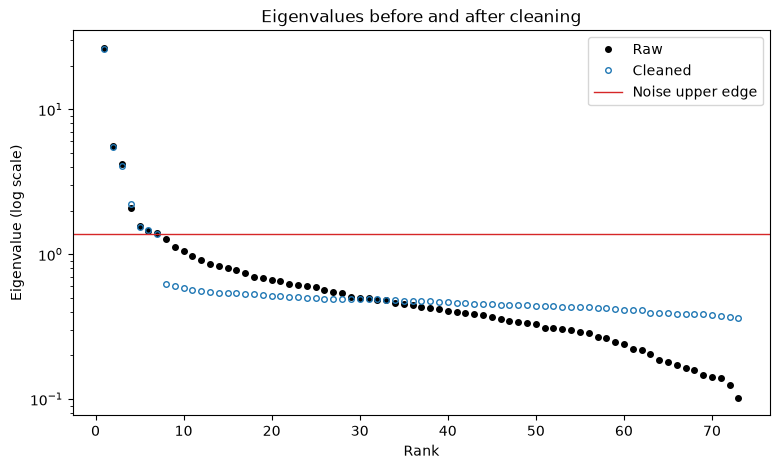

In [11]:
Cc = clean_corr(C, q)

fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogy(range(1, N + 1), w, "o", ms=4, color="black", label="Raw")
ax.semilogy(range(1, N + 1), eig(Cc)[0], "o", ms=4, mfc="none", color="tab:blue", label="Cleaned")
ax.axhline(hi, color="tab:red", lw=1, label="Noise upper edge")
ax.set_xlabel("Rank")
ax.set_ylabel("Eigenvalue (log scale)")
ax.set_title("Eigenvalues before and after cleaning")
ax.legend()
plt.savefig("../figures/cleaned_spectrum.png", dpi=150, bbox_inches="tight")

**How to read this figure:** The black dots are the original eigenvalues and the blue circles are the eigenvalues after cleaning.
The seven above the red line were kept, and everything below it was pulled towards a common value. The cleaned values aren’t perfectly flat because of the final rescaling step, but the long tail of very small eigenvalues, the ones the optimiser would otherwise exploit, is gone.

In [12]:
X = R.to_numpy()
rows = []
for s in range(0, T - 2 * 252 + 1, 252):
    tr, te = X[s:s + 252], X[s + 252:s + 504]
    St = np.cov(te, rowvar=False)
    for name, S in [("raw", np.cov(tr, rowvar=False)), ("cleaned", clean_cov(tr))]:
        p = min_var(S)
        rows.append({"test year starts": R.index[s + 252].date(), "matrix": name,
                     "predicted vol": np.sqrt(252 * p @ S @ p), "realised vol": np.sqrt(252 * p @ St @ p)})

oos = pd.DataFrame(rows)
oos["realised / predicted"] = oos["realised vol"] / oos["predicted vol"]
oos.pivot(index="test year starts", columns="matrix").round(3)

predicted vol        realised vol         \
matrix                 cleaned    raw      cleaned    raw   
test year starts                                            
2017-09-27               0.052  0.046        0.096  0.110   
2018-09-27               0.071  0.070        0.126  0.144   
2019-09-30               0.095  0.094        0.443  0.374   
2020-09-29               0.150  0.137        0.149  0.169   
2021-09-29               0.084  0.083        0.166  0.159   
2022-09-29               0.119  0.101        0.132  0.154   
2023-10-02               0.096  0.090        0.121  0.138   
2024-10-02               0.068  0.067        0.128  0.133   

                 realised / predicted         
matrix                        cleaned    raw  
test year starts                              
2017-09-27                      1.840  2.378  
2018-09-27                      1.775  2.049  
2019-09-30                      4.659  3.981  
2020-09-29                      0.988  1.240  
2021-09-29                      1.986  1.926  
2022-09-29                      1.114  1.530  
2023-10-02                      1.253  1.530  
2024-10-02                      1.895  1.977

**How to read these tables:** Each row is one test year, and the portfolio for that year was built from the year before it. For each matrix, raw and cleaned, the table shows the volatility the matrix predicted, the volatility the portfolio actually had over the test year, and the ratio of the two. A ratio of 1 would mean the matrix got the risk exactly right; anything above 1 means it underestimated the risk. The second table averages each column over the eight years.

In [13]:
oos.groupby("matrix")[["predicted vol", "realised vol", "realised / predicted"]].mean().round(3)

,predicted vol,realised vol,realised / predicted
matrix,,,
cleaned,0.092,0.170,1.939
raw,0.086,0.173,2.076


In [14]:
p = oos.pivot(index="test year starts", columns="matrix", values="realised vol")
pd.Series({
    "years cleaned had lower realised vol": (p["cleaned"] < p["raw"]).sum(),
    "out of": len(p),
    "median change in realised vol": (p["cleaned"] / p["raw"] - 1).median(),
}).round(3)

years cleaned had lower realised vol    6.000
out of                                  8.000
median change in realised vol          -0.123
dtype: float64

**What we found:** Cleaning helped in most years, but not by as much as I’d hoped. The cleaned matrix gave lower realised volatility in 6 of the 8 test years, typically by about 12%. The exception was the year that ran into COVID (the test year starting in September 2019): both portfolios were caught out, with realised risk around four times what they predicted, and the cleaned one did worse. That single year pulled the average improvement down to under 2%. The bigger surprise was how overconfident both matrices were. On average, realised risk was about twice the predicted risk, for the cleaned matrix as well as the raw one. Estimation noise alone would explain a ratio of roughly 1.4 for one-year windows, so most of the gap came from something else: markets changed between the year I estimated the matrix and the year I held the portfolio. No cleaning method can fix that, because the problem isn’t noise but the future being different from the past. These portfolios allowed short positions, so they show the pure effect of the matrix. The full backtest in the next notebook rebalances monthly, which should cut down the effect of changing markets, adds Ledoit-Wolf shrinkage as a benchmark and looks at realistic long-only portfolios.

## 6. The market mode over time

So far I’ve looked at the whole ten years at once. But the EDA showed that correlations rise sharply in crises, so I wanted to see how the eigenvalues themselves change over time. I recomputed the correlation matrix over a rolling one-year window, moving forward a month at a time, and tracked two things: the market mode’s share of the total variance (λ₁/N), and how many eigenvalues cleared the noise edge in each window.

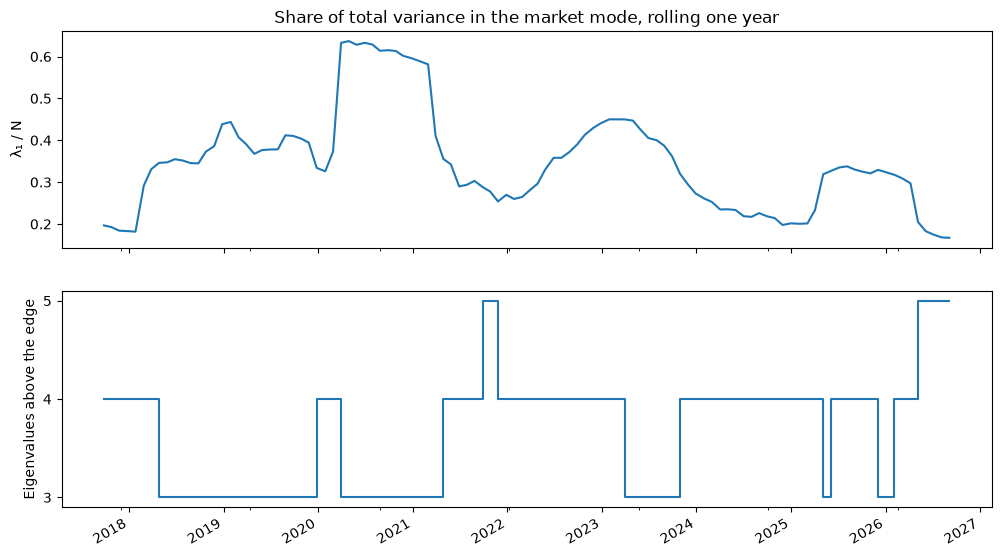

In [15]:
win, rows = 252, []
for e in range(win, T + 1, 21):
    we = eig(np.corrcoef(X[e - win:e], rowvar=False))[0]
    rows.append({"date": R.index[e - 1], "market share": we[0] / N, "signal": n_signal(we, N / win)})
roll = pd.DataFrame(rows).set_index("date")

fig, (a, b) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
roll["market share"].plot(ax=a)
a.set_ylabel("λ₁ / N")
a.set_title("Share of total variance in the market mode, rolling one year")
roll["signal"].plot(ax=b, drawstyle="steps-post")
b.set_ylabel("Eigenvalues above the edge")
b.set_xlabel("")
b.set_yticks(range(roll["signal"].min(), roll["signal"].max() + 1))
plt.savefig("../figures/rolling_market_mode.png", dpi=150, bbox_inches="tight")

**How to read this figure:** Each point uses the previous year of data and is plotted at the end of that year. The top panel shows how much of the total variance the market mode explained, and the bottom panel shows how many eigenvalues sat above the noise edge. With only a year of data, that edge rises to 2.37, compared with 1.37 for the full sample.

**What we found:** The market mode’s share moved a lot, from about 0.17 in the calmest windows to 0.63 in the window covering the COVID crash. Each crisis shows up as a step up when it enters the window and a step down exactly a year later when it leaves, which is why the COVID plateau ends so abruptly in early 2021. The other jumps line up with the events in the EDA’s rolling correlation chart: the 2018 sell-offs, the 2022 rate hikes and the 2025 tariff shock.

The bottom panel shows that with only a year of data, just 3 to 5 factors stood out from the noise, instead of the 7 I found over the full ten years: the weaker factors got lost in the wider noise band. The two panels also tended to move in opposite directions. When the market factor dominated, only three factors stood out, and in calmer periods five did. In a crisis everything moves together and the sector structure gets swallowed by the market.

This matters for the backtest, because it’s exactly the setting the cleaning has to work in: one-year windows where only a handful of factors can be trusted and the rest of the matrix is mostly noise.

## 7. Conclusions

Going into this notebook, I wanted to know how much of the correlation matrix I could actually trust. Before running anything, the EDA had predicted a largest eigenvalue of about 25, implied by an average correlation of about a third, with financials as the most connected sector. The actual value was 26.5, and financials did carry the most weight in the market mode. That one eigenvalue carried 36% of the total variance on its own. Six more eigenvalues cleared the noise edge, and the shuffle test confirmed they weren’t an artifact of fat tails. Without ever being told which sector each stock belonged to, their eigenvectors recovered familiar economic groupings: defensive against cyclical, growth against value, pharma against interest-rate-sensitive stocks, and commodities against banks. The usual rule of thumb in PCA is to keep any eigenvalue above 1, which would have kept ten factors here. But the eigenvalues ranked eighth to tenth (1.27, 1.12 and 1.05) sit inside the noise band, so they can’t be told apart from noise. Random matrix theory gives a threshold that accounts for how much data I have.

The biggest surprise was at the other end of the spectrum. 55 eigenvalues fell below the noise band, so in total 62 of the 73 sat outside the range that pure noise can produce. The smallest ones turned out to be pairs of near-identical companies, like Bank of America and JPMorgan, where going long one and short the other leaves almost no risk. With ten years of data, then, most of the matrix is real structure, and estimation noise isn’t the main problem.

That changes with a single year of data, which is how a portfolio is actually built in practice. With only 252 days, the noise edge rises from 1.37 to 2.37, so an eigenvalue has to be much larger to count as real. In one-year windows only three to five factors cleared it, and the market factor’s share swung between 17% and 63% depending on whether a crisis fell inside the window. In a simple year-by-year test, cleaning the matrix gave lower realized volatility in six of the eight years, typically by about 12%, and made the optimizer a little less overconfident. But both the raw and cleaned matrices still underestimated risk by roughly a factor of two, mostly because markets changed from one year to the next. For an investor, the lesson is that owning many stocks isn’t the same as being diversified. Seventy-three large US stocks behaved, to a large extent, like one bet on the market, and in a crisis that single bet came to dominate even more.

It is important to note that there are limits to what this notebook shows. Eigenvalue clipping flattens real structure as well as noise, including those near-twin pairs; the test used portfolios that allowed short positions and were held for a whole year; and the universe has survivorship bias. The next notebook tests the idea properly, with monthly rebalancing, realistic long-only portfolios, and Ledoit-Wolf shrinkage as a benchmark, to see whether cleaning the matrix really leads to lower-risk portfolios.